# 05 &nbsp;What happens if we peek every day?

**The problem.** Nobody waits two weeks without looking. Dashboards update daily, someone sees a green number on day 4, and the test gets called. Each look is another chance for noise to cross the line, so a test that promises 5% false alarms quietly delivers far more.

**The approach.** Simulate it on real data, then fix it.

1. Run thousands of **A/A tests** on real no-email customers, spread over 14 days, and look every day. Nothing changed, so every "winner" is a false alarm.
2. Compare three ways of running the test: **look once** at the end, **peek daily** and stop at the first significant result, and a **sequential design** that allows daily looks but sets a stricter bar early on.
3. Check what the sequential design costs when there *is* a real lift: how often it catches it, and how early it can stop.

*Simplification:* customers enter evenly over 14 days and their outcome is known right away. In a live email test outcomes take time to arrive, which makes early looks even noisier, so these results are if anything kind to peeking.

In [1]:
import numpy as np
import pandas as pd

from exptoolkit import plots, style
from exptoolkit.data import load_hillstrom
from exptoolkit.sequential import naive_boundaries, obf_boundaries, run_sequential
from exptoolkit.spec import load_spec

style.use_style()
spec = load_spec("hillstrom_email.yaml")
alpha = spec.statistics["alpha"]

df = load_hillstrom()
spend = df.loc[df["arm"] == "control", "spend"]
n_per_arm = int(df["arm"].value_counts().min())
days = 14

## 1. The bar for calling a winner

Peeking uses the same bar every day (a z score of 1.96, the usual p < 0.05). The sequential design uses an **O'Brien-Fleming** shaped bar: very strict when there is little data, relaxing to almost the usual bar by the last day. Its exact height is found by simulation so the overall false alarm rate is 5% across all 14 looks.

In [2]:
peek_bar = naive_boundaries(days, alpha)
sequential_bar = obf_boundaries(days, alpha)
look_once_bar = np.full(days, np.inf)
look_once_bar[-1] = peek_bar[-1]

pd.DataFrame({"Peek daily": peek_bar, "Sequential": sequential_bar},
             index=pd.Index(range(1, days + 1), name="Day")).T.round(2)

Day,1,2,3,4,5,6,7,8,9,10,11,12,13,14
Peek daily,1.96,1.96,1.96,1.96,1.96,1.96,1.96,1.96,1.96,1.96,1.96,1.96,1.96,1.96
Sequential,7.88,5.57,4.55,3.94,3.52,3.22,2.98,2.79,2.63,2.49,2.38,2.27,2.19,2.11


## 2. False alarms when nothing changed

10,000 two-week A/A tests for each way of running the test.

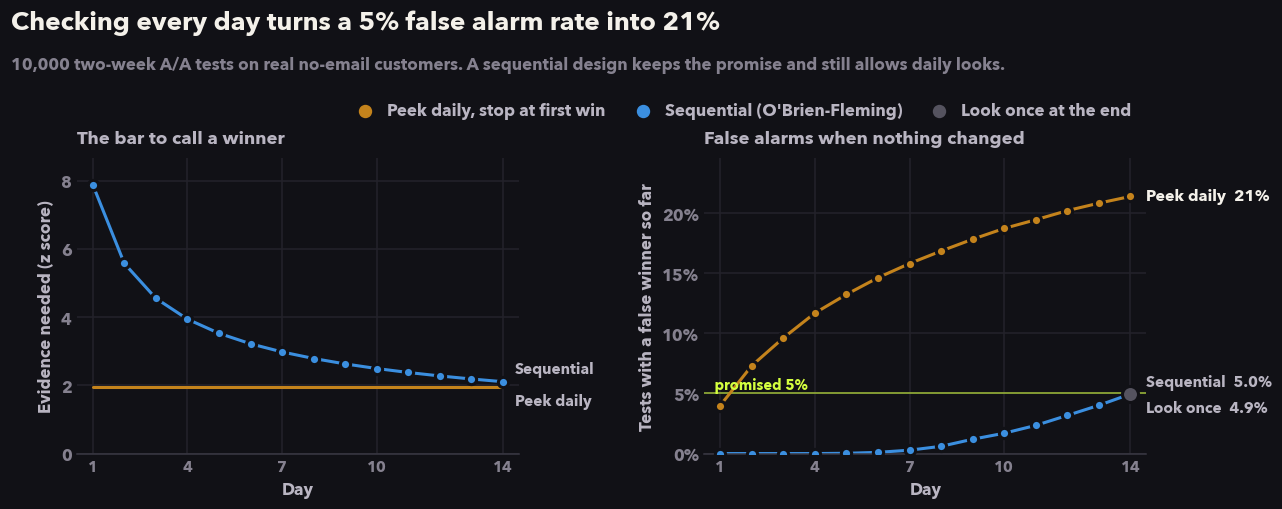

In [3]:
aa = {name: run_sequential(spend, bar, n_per_arm, n_sims=10_000, seed=1)
      for name, bar in [("peek", peek_bar), ("sequential", sequential_bar), ("once", look_once_bar)]}

fig, _ = plots.peeking_plot(peek_bar, sequential_bar, aa["peek"].crossed_by_look,
                            aa["sequential"].crossed_by_look, aa["once"].rejection_rate, alpha)
style.headline(
    fig,
    f"Checking every day turns a 5% false alarm rate into {aa['peek'].rejection_rate:.0%}",
    "10,000 two-week A/A tests on real no-email customers. "
    "A sequential design keeps the promise and still allows daily looks.",
)
style.save(fig, "peeking")

In [4]:
pd.DataFrame({
    "False alarm rate": [aa[k].rejection_rate for k in ["once", "peek", "sequential"]],
}, index=["Look once at the end", "Peek daily, stop at first win", "Sequential (O'Brien-Fleming)"]
).style.format("{:.1%}")

,False alarm rate
Look once at the end,4.9%
"Peek daily, stop at first win",21.4%
Sequential (O'Brien-Fleming),5.0%


Peeking daily raised a false winner in about **1 in 5** tests where nothing changed, four times the promised rate. About three quarters of those false winners appear in the first week, exactly when the urge to call a test is strongest. The sequential design holds the line at 5%, the same as waiting until the end.

## 3. What does safety cost when the lift is real?

A sequential design is only worth it if it doesn't throw away the ability to find real effects. Here a true lift of **40 cents per customer** is added, about the size notebook 01 suggested for the women's email, using the same "more buyers" approach as notebook 04.

In [5]:
real_lift = 0.40
rows = []
for name, bar in [("Look once at the end", look_once_bar),
                  ("Sequential (O'Brien-Fleming)", sequential_bar)]:
    r = run_sequential(spend, bar, n_per_arm, n_sims=4_000, revenue_lift=real_lift, seed=2)
    rows.append({"": name, "Caught the lift": r.rejection_rate, "Average day of decision": r.average_stop})
cost = pd.DataFrame(rows).set_index("")
cost.style.format({"Caught the lift": "{:.1%}", "Average day of decision": "{:.1f}"})

,Caught the lift,Average day of decision
,,
Look once at the end,88.5%,14.0
Sequential (O'Brien-Fleming),87.3%,9.9


## What this tells us

- **Daily peeking is not a small sin.** With 14 looks, a 5% test becomes a roughly 21% test. Most "early wins" called this way are noise.
- **Looking is fine if the bar moves.** The sequential design allows the same daily dashboard and keeps false alarms at 5%.
- **The cost is small and the payoff is speed.** On a real 40 cent lift, the sequential design catches it almost as often as waiting the full two weeks, and on average decides about **4 days sooner**. Bigger lifts stop even earlier.
- **The rule has to be set before the test starts.** A sequential design chosen after a peek is just peeking with extra steps. In a live test the number of looks and the boundary would go into the decision plan from notebook 02.

## Next

Notebook 06 does the formal readout of the email test itself: effects with intervals, the correction for secondary metrics set in the plan, and variance reduction using customers' past spend.